Spatio-Temporal Crime Risk Prediction
Goal:

Predict future crime intensity for geographic areas using historical spatial and temporal crime patterns.

The model works at an aggregated geographic and weekly level rather than attempting to predict individual crime events.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
df = pd.read_csv(
    "../data/crimes_features.csv"
)

df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)

print("Shape:", df.shape)
print("Start:", df['date'].min())
print("End:", df['date'].max())

Shape: (1388164, 27)
Start: 2021-01-01 00:00:00
End: 2026-10-03 00:00:00


In [4]:
spatial = df[
    [
        'date',
        'latitude',
        'longitude'
    ]
].dropna().copy()

spatial = spatial[
    spatial['latitude'].between(-90, 90)
    &
    spatial['longitude'].between(-180, 180)
]

print("Valid records:", len(spatial))

Valid records: 1367657


In [5]:
spatial['grid_lat'] = (
    spatial['latitude']
    .round(3)
)

spatial['grid_lon'] = (
    spatial['longitude']
    .round(3)
)

In [6]:
spatial['grid_id'] = (
    spatial['grid_lat'].astype(str)
    + "_"
    + spatial['grid_lon'].astype(str)
)

print(
    "Number of geographic cells:",
    spatial['grid_id'].nunique()
)

spatial[
    [
        'grid_id',
        'grid_lat',
        'grid_lon'
    ]
].head()

Number of geographic cells: 42119


,grid_id,grid_lat,grid_lon
0,41.809_-87.617,41.809,-87.617
1,41.886_-87.747,41.886,-87.747
2,41.858_-87.705,41.858,-87.705
3,41.771_-87.586,41.771,-87.586
4,41.737_-87.544,41.737,-87.544


In [7]:
spatial['week'] = (
    spatial['date']
    .dt.to_period('W')
    .dt.start_time
)

spatial[
    ['date', 'week']
].head()

,date,week
0,2021-01-01 03:48:00,2020-12-28
1,2021-01-01 18:06:00,2020-12-28
2,2021-01-02 21:55:00,2020-12-28
3,2021-01-03 20:09:00,2020-12-28
4,2021-01-03 21:28:00,2020-12-28


In [8]:
grid_week = (
    spatial
    .groupby(
        [
            'week',
            'grid_id',
            'grid_lat',
            'grid_lon'
        ],
        sort=False
    )
    .size()
    .reset_index(
        name='crime_count'
    )
)

print("Grid-week observations:", len(grid_week))

grid_week.head()

Grid-week observations: 1095958


,week,grid_id,grid_lat,grid_lon,crime_count
0,2020-12-28,41.809_-87.617,41.809,-87.617,2
1,2020-12-28,41.886_-87.747,41.886,-87.747,2
2,2020-12-28,41.858_-87.705,41.858,-87.705,1
3,2020-12-28,41.771_-87.586,41.771,-87.586,1
4,2020-12-28,41.737_-87.544,41.737,-87.544,1


In [9]:
grid_week['crime_count'].describe()

count    1.095958e+06
mean     1.247910e+00
std      7.893583e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      2.650000e+02
Name: crime_count, dtype: float64

In [10]:
top_cells = (
    spatial['grid_id']
    .value_counts()
    .head(20)
)

top_cells

grid_id
41.882_-87.628    3099
41.976_-87.905    1689
41.884_-87.628    1611
41.867_-87.626    1492
41.789_-87.741    1415
41.755_-87.742    1385
41.963_-87.656    1200
41.778_-87.616    1130
41.892_-87.626    1127
41.868_-87.63     1080
41.885_-87.628    1065
41.893_-87.633    1041
41.895_-87.622    1015
41.776_-87.616     983
41.869_-87.639     952
41.93_-87.684      936
42.019_-87.675     927
41.977_-87.901     925
41.736_-87.628     884
41.883_-87.628     872
Name: count, dtype: int64

In [11]:
grid_tests = []

for decimals in [3, 2]:

    test = spatial.copy()

    test['grid_lat_test'] = (
        test['latitude'].round(decimals)
    )

    test['grid_lon_test'] = (
        test['longitude'].round(decimals)
    )

    test['grid_id_test'] = (
        test['grid_lat_test'].astype(str)
        + "_"
        + test['grid_lon_test'].astype(str)
    )

    temp = (
        test
        .groupby(
            ['week', 'grid_id_test'],
            sort=False
        )
        .size()
    )

    grid_tests.append({
        'decimals': decimals,
        'cells': test['grid_id_test'].nunique(),
        'observations': len(temp),
        'mean_crimes': temp.mean(),
        'median_crimes': temp.median(),
        'p75_crimes': temp.quantile(0.75),
        'max_crimes': temp.max()
    })

grid_comparison = pd.DataFrame(grid_tests)

grid_comparison

,decimals,cells,observations,mean_crimes,median_crimes,p75_crimes,max_crimes
0,3,42119,1095958,1.247910,1.0,1.0,265
1,2,734,172420,7.932125,6.0,11.0,326


In [12]:
spatial['grid_lat'] = spatial['latitude'].round(2)
spatial['grid_lon'] = spatial['longitude'].round(2)

spatial['grid_id'] = (
    spatial['grid_lat'].astype(str)
    + "_"
    + spatial['grid_lon'].astype(str)
)

print("Final grid cells:", spatial['grid_id'].nunique())

Final grid cells: 734


In [13]:
observed = (
    spatial
    .groupby(
        ['week', 'grid_id'],
        sort=False
    )
    .size()
    .rename('crime_count')
)

In [14]:
weeks = pd.date_range(
    spatial['week'].min(),
    spatial['week'].max(),
    freq='7D'
)

grid_ids = spatial['grid_id'].unique()

full_index = pd.MultiIndex.from_product(
    [weeks, grid_ids],
    names=['week', 'grid_id']
)

grid_week = (
    observed
    .reindex(full_index, fill_value=0)
    .reset_index()
)


In [15]:
grid_coordinates = (
    spatial
    .groupby('grid_id')
    [['grid_lat', 'grid_lon']]
    .first()
    .reset_index()
)

grid_week = grid_week.merge(
    grid_coordinates,
    on='grid_id',
    how='left'
)

In [16]:
print("Dataset shape:", grid_week.shape)

zero_rate = (
    grid_week['crime_count'].eq(0).mean() * 100
)

print(f"Zero rate: {zero_rate:.2f}%")

grid_week['crime_count'].describe()

Dataset shape: (220934, 5)
Zero rate: 21.96%


count    220934.000000
mean          6.190342
std           7.631163
min           0.000000
25%           1.000000
50%           4.000000
75%           9.000000
max         326.000000
Name: crime_count, dtype: float64

In [17]:
grid_week = grid_week.sort_values(
    ['grid_id', 'week']
).reset_index(drop=True)

grid_week.head()

,week,grid_id,crime_count,grid_lat,grid_lon
0,2020-12-28,36.62_-91.69,0,36.62,-91.69
1,2021-01-04,36.62_-91.69,0,36.62,-91.69
2,2021-01-11,36.62_-91.69,0,36.62,-91.69
3,2021-01-18,36.62_-91.69,0,36.62,-91.69
4,2021-01-25,36.62_-91.69,0,36.62,-91.69


In [18]:
grid_week['week_of_year'] = (
    grid_week['week'].dt.isocalendar().week.astype(int)
)

grid_week['month'] = grid_week['week'].dt.month
grid_week['year'] = grid_week['week'].dt.year

grid_week['week_sin'] = np.sin(
    2 * np.pi * grid_week['week_of_year'] / 52
)

grid_week['week_cos'] = np.cos(
    2 * np.pi * grid_week['week_of_year'] / 52
)

grid_week['month_sin'] = np.sin(
    2 * np.pi * (grid_week['month'] - 1) / 12
)

grid_week['month_cos'] = np.cos(
    2 * np.pi * (grid_week['month'] - 1) / 12
)

In [19]:
grouped = grid_week.groupby(
    'grid_id'
)['crime_count']

grid_week['lag_1'] = grouped.shift(1)
grid_week['lag_2'] = grouped.shift(2)
grid_week['lag_4'] = grouped.shift(4)
grid_week['lag_8'] = grouped.shift(8)
grid_week['lag_12'] = grouped.shift(12)

In [20]:
grid_week['rolling_4_mean'] = (
    grid_week
    .groupby('grid_id')['crime_count']
    .transform(
        lambda x:
            x.shift(1)
             .rolling(4)
             .mean()
    )
)

grid_week['rolling_8_mean'] = (
    grid_week
    .groupby('grid_id')['crime_count']
    .transform(
        lambda x:
            x.shift(1)
             .rolling(8)
             .mean()
    )
)

grid_week['rolling_4_std'] = (
    grid_week
    .groupby('grid_id')['crime_count']
    .transform(
        lambda x:
            x.shift(1)
             .rolling(4)
             .std()
    )
)

In [21]:
grid_week['historical_mean'] = (
    grid_week
    .groupby('grid_id')['crime_count']
    .transform(
        lambda x:
            x.shift(1)
             .expanding()
             .mean()
    )
)

In [22]:
model_data = grid_week.dropna().copy()

print("ML observations:", len(model_data))
print("Cells:", model_data['grid_id'].nunique())

model_data[
    [
        'week',
        'grid_id',
        'crime_count',
        'lag_1',
        'lag_4',
        'rolling_4_mean',
        'historical_mean'
    ]
].head(10)

ML observations: 212126
Cells: 734


,week,grid_id,crime_count,lag_1,lag_4,rolling_4_mean,historical_mean
12,2021-03-22,36.62_-91.69,0,0.0,0.0,0.0,0.0
13,2021-03-29,36.62_-91.69,0,0.0,0.0,0.0,0.0
14,2021-04-05,36.62_-91.69,0,0.0,0.0,0.0,0.0
15,2021-04-12,36.62_-91.69,0,0.0,0.0,0.0,0.0
16,2021-04-19,36.62_-91.69,0,0.0,0.0,0.0,0.0
17,2021-04-26,36.62_-91.69,0,0.0,0.0,0.0,0.0
18,2021-05-03,36.62_-91.69,0,0.0,0.0,0.0,0.0
19,2021-05-10,36.62_-91.69,0,0.0,0.0,0.0,0.0
20,2021-05-17,36.62_-91.69,0,0.0,0.0,0.0,0.0
21,2021-05-24,36.62_-91.69,0,0.0,0.0,0.0,0.0


In [23]:
features = [
    'grid_lat',
    'grid_lon',

    'week_of_year',
    'month',
    'year',

    'week_sin',
    'week_cos',
    'month_sin',
    'month_cos',

    'lag_1',
    'lag_2',
    'lag_4',
    'lag_8',
    'lag_12',

    'rolling_4_mean',
    'rolling_8_mean',
    'rolling_4_std',

    'historical_mean'
]

X = model_data[features]
y = model_data['crime_count']

print("X:", X.shape)
print("y:", y.shape)

X: (212126, 18)
y: (212126,)


In [24]:
unique_weeks = np.sort(
    model_data['week'].unique()
)

split_idx = int(
    len(unique_weeks) * 0.8
)

split_week = unique_weeks[split_idx]

train_mask = (
    model_data['week'] < split_week
)

test_mask = (
    model_data['week'] >= split_week
)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print()
print(
    "Train:",
    model_data.loc[train_mask, 'week'].min(),
    "→",
    model_data.loc[train_mask, 'week'].max()
)

print(
    "Test:",
    model_data.loc[test_mask, 'week'].min(),
    "→",
    model_data.loc[test_mask, 'week'].max()
)

Train: (169554, 18)
Test: (42572, 18)

Train: 2021-03-22 00:00:00 → 2025-08-18 00:00:00
Test: 2025-08-25 00:00:00 → 2026-09-28 00:00:00


In [25]:
baseline_pred = model_data.loc[
    test_mask,
    'lag_1'
].values

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_pred
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

print("BASELINE")
print("----------------")
print(f"MAE:  {baseline_mae:.3f}")
print(f"RMSE: {baseline_rmse:.3f}")
print(f"R²:   {baseline_r2:.4f}")

BASELINE
----------------
MAE:  2.524
RMSE: 3.929
R²:   0.7288


In [26]:
area_model = HistGradientBoostingRegressor(
    loss='poisson',
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

area_model.fit(
    X_train,
    y_train
)

print("Area-risk model trained ✅")

Area-risk model trained ✅


In [27]:
area_pred = area_model.predict(X_test)

area_pred = np.maximum(
    area_pred,
    0
)

In [28]:
area_mae = mean_absolute_error(
    y_test,
    area_pred
)

area_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        area_pred
    )
)

area_r2 = r2_score(
    y_test,
    area_pred
)

print("AREA MODEL")
print("----------------")
print(f"MAE:  {area_mae:.3f}")
print(f"RMSE: {area_rmse:.3f}")
print(f"R²:   {area_r2:.4f}")

AREA MODEL
----------------
MAE:  1.923
RMSE: 2.947
R²:   0.8474


In [29]:
comparison = pd.DataFrame({
    'Model': [
        'Previous Week Baseline',
        'HistGradientBoosting'
    ],
    'MAE': [
        baseline_mae,
        area_mae
    ],
    'RMSE': [
        baseline_rmse,
        area_rmse
    ],
    'R2': [
        baseline_r2,
        area_r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Previous Week Baseline,2.524476,3.928923,0.728816
1,HistGradientBoosting,1.923136,2.947046,0.847423


In [30]:
test_results = model_data.loc[
    test_mask,
    [
        'week',
        'grid_id',
        'grid_lat',
        'grid_lon',
        'crime_count'
    ]
].copy()

test_results['predicted_crimes'] = area_pred

test_results['baseline'] = baseline_pred

test_results['absolute_error'] = (
    test_results['crime_count']
    - test_results['predicted_crimes']
).abs()

test_results.head()

,week,grid_id,grid_lat,grid_lon,crime_count,predicted_crimes,baseline,absolute_error
243,2025-08-25,36.62_-91.69,36.62,-91.69,0,0.017629,0.0,0.017629
244,2025-09-01,36.62_-91.69,36.62,-91.69,0,0.017477,0.0,0.017477
245,2025-09-08,36.62_-91.69,36.62,-91.69,0,0.017468,0.0,0.017468
246,2025-09-15,36.62_-91.69,36.62,-91.69,0,0.024078,0.0,0.024078
247,2025-09-22,36.62_-91.69,36.62,-91.69,0,0.024078,0.0,0.024078


In [31]:
test_results[
    [
        'crime_count',
        'predicted_crimes',
        'absolute_error'
    ]
].describe()

,crime_count,predicted_crimes,absolute_error
count,42572.000000,42572.000000,42572.000000
mean,6.037020,6.171535,1.923136
std,7.544787,7.055816,2.233103
min,0.000000,0.015645,0.000029
25%,1.000000,1.183319,0.406565
50%,4.000000,4.334120,1.214012
75%,9.000000,8.818840,2.656671
max,108.000000,89.777548,38.707039


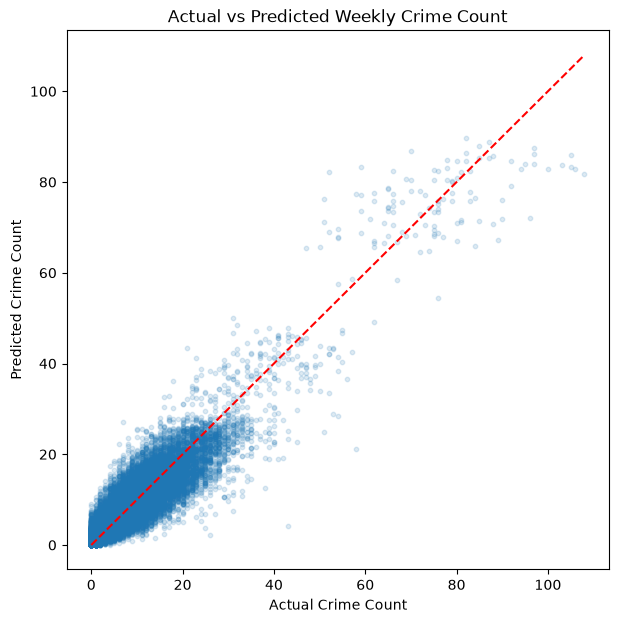

In [32]:
plt.figure(figsize=(7, 7))

plt.scatter(
    test_results['crime_count'],
    test_results['predicted_crimes'],
    alpha=0.15,
    s=10
)

max_value = max(
    test_results['crime_count'].max(),
    test_results['predicted_crimes'].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle='--',
    color='red'
)

plt.xlabel('Actual Crime Count')
plt.ylabel('Predicted Crime Count')
plt.title('Actual vs Predicted Weekly Crime Count')

plt.show()

In [33]:
all_weeks = np.sort(
    model_data['week'].unique()
)

n_folds = 4
week_blocks = np.array_split(
    all_weeks,
    n_folds + 1
)

cv_results = []

for fold in range(1, n_folds + 1):

    train_weeks = np.concatenate(
        week_blocks[:fold]
    )

    val_weeks = week_blocks[fold]

    train_mask_cv = (
        model_data['week'].isin(train_weeks)
    )

    val_mask_cv = (
        model_data['week'].isin(val_weeks)
    )

    X_train_cv = X.loc[train_mask_cv]
    y_train_cv = y.loc[train_mask_cv]

    X_val_cv = X.loc[val_mask_cv]
    y_val_cv = y.loc[val_mask_cv]

    model_cv = HistGradientBoostingRegressor(
        loss='poisson',
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )

    model_cv.fit(
        X_train_cv,
        y_train_cv
    )

    pred_cv = model_cv.predict(
        X_val_cv
    )

    pred_cv = np.maximum(
        pred_cv,
        0
    )

    baseline_cv = model_data.loc[
        val_mask_cv,
        'lag_1'
    ].values

    cv_results.append({
        'fold': fold,

        'start_week':
            val_weeks.min(),

        'end_week':
            val_weeks.max(),

        'model_MAE':
            mean_absolute_error(
                y_val_cv,
                pred_cv
            ),

        'baseline_MAE':
            mean_absolute_error(
                y_val_cv,
                baseline_cv
            ),

        'model_RMSE':
            np.sqrt(
                mean_squared_error(
                    y_val_cv,
                    pred_cv
                )
            ),

        'baseline_RMSE':
            np.sqrt(
                mean_squared_error(
                    y_val_cv,
                    baseline_cv
                )
            ),

        'model_R2':
            r2_score(
                y_val_cv,
                pred_cv
            ),

        'baseline_R2':
            r2_score(
                y_val_cv,
                baseline_cv
            )
    })

In [34]:
cv_area = pd.DataFrame(
    cv_results
)

cv_area

,fold,start_week,end_week,model_MAE,baseline_MAE,model_RMSE,baseline_RMSE,model_R2,baseline_R2
0,1,2022-05-02,2023-06-05,2.036543,2.622334,3.525032,4.535069,0.803219,0.674294
1,2,2023-06-12,2024-07-15,2.080431,2.685145,3.250787,4.270916,0.844848,0.732193
2,3,2024-07-22,2025-08-25,1.988032,2.562647,3.002413,3.944809,0.857044,0.753218
3,4,2025-09-01,2026-09-28,1.915536,2.521225,2.945144,3.925233,0.847651,0.729382


In [35]:
print("AREA MODEL - TEMPORAL CV")
print("------------------------")

print(
    f"Model MAE: "
    f"{cv_area['model_MAE'].mean():.3f}"
)

print(
    f"Baseline MAE: "
    f"{cv_area['baseline_MAE'].mean():.3f}"
)

print()

print(
    f"Model RMSE: "
    f"{cv_area['model_RMSE'].mean():.3f}"
)

print(
    f"Baseline RMSE: "
    f"{cv_area['baseline_RMSE'].mean():.3f}"
)

print()

print(
    f"Model R²: "
    f"{cv_area['model_R2'].mean():.4f}"
)

print(
    f"Baseline R²: "
    f"{cv_area['baseline_R2'].mean():.4f}"
)

print()

print(
    f"Model R² std: "
    f"{cv_area['model_R2'].std():.4f}"
)

AREA MODEL - TEMPORAL CV
------------------------
Model MAE: 2.005
Baseline MAE: 2.598

Model RMSE: 3.181
Baseline RMSE: 4.169

Model R²: 0.8382
Baseline R²: 0.7223

Model R² std: 0.0239


In [36]:
mae_improvement = (
    (
        cv_area['baseline_MAE'].mean()
        - cv_area['model_MAE'].mean()
    )
    / cv_area['baseline_MAE'].mean()
    * 100
)

rmse_improvement = (
    (
        cv_area['baseline_RMSE'].mean()
        - cv_area['model_RMSE'].mean()
    )
    / cv_area['baseline_RMSE'].mean()
    * 100
)

print(
    f"MAE improvement: "
    f"{mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{rmse_improvement:.2f}%"
)

MAE improvement: 22.82%
RMSE improvement: 23.70%


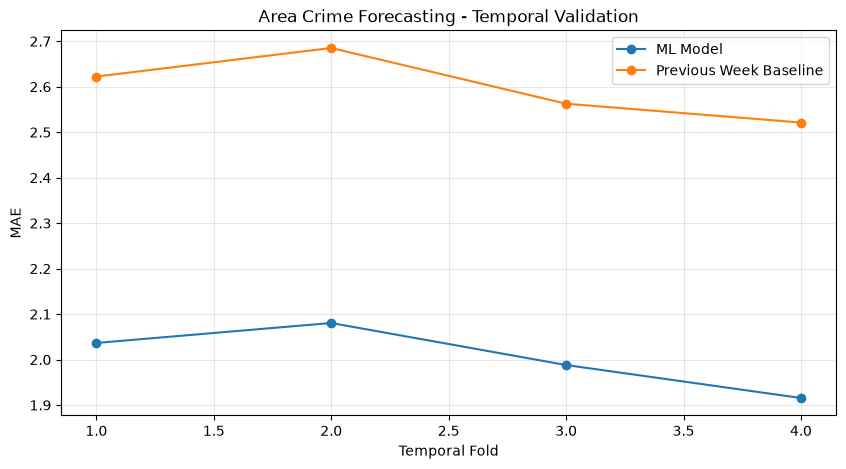

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    cv_area['fold'],
    cv_area['model_MAE'],
    marker='o',
    label='ML Model'
)

plt.plot(
    cv_area['fold'],
    cv_area['baseline_MAE'],
    marker='o',
    label='Previous Week Baseline'
)

plt.xlabel('Temporal Fold')
plt.ylabel('MAE')

plt.title(
    'Area Crime Forecasting - Temporal Validation'
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [38]:
final_area_model = HistGradientBoostingRegressor(
    loss='poisson',
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

final_area_model.fit(
    X,
    y
)

print("Final area-risk model trained ✅")


Final area-risk model trained ✅


In [39]:
model_data['predicted_crimes'] = (
    final_area_model.predict(X)
)

model_data['predicted_crimes'] = (
    model_data['predicted_crimes']
    .clip(lower=0)
)

In [40]:
model_data['predicted_crimes'] = (
    final_area_model.predict(X)
)

model_data['predicted_crimes'] = (
    model_data['predicted_crimes']
    .clip(lower=0)
)

In [41]:
low_threshold = (
    model_data['predicted_crimes']
    .quantile(0.50)
)

high_threshold = (
    model_data['predicted_crimes']
    .quantile(0.80)
)

print(
    "Low/Medium threshold:",
    round(low_threshold, 2)
)

print(
    "Medium/High threshold:",
    round(high_threshold, 2)
)

Low/Medium threshold: 4.41
Medium/High threshold: 10.65


In [42]:
def assign_risk(value):

    if value >= high_threshold:
        return 'HIGH'

    elif value >= low_threshold:
        return 'MEDIUM'

    else:
        return 'LOW'

In [43]:
model_data['risk_level'] = (
    model_data['predicted_crimes']
    .apply(assign_risk)
)

model_data[
    [
        'week',
        'grid_id',
        'crime_count',
        'predicted_crimes',
        'risk_level'
    ]
].head(20)

,week,grid_id,crime_count,predicted_crimes,risk_level
12,2021-03-22,36.62_-91.69,0,0.022470,LOW
13,2021-03-29,36.62_-91.69,0,0.026298,LOW
14,2021-04-05,36.62_-91.69,0,0.015329,LOW
15,2021-04-12,36.62_-91.69,0,0.015369,LOW
16,2021-04-19,36.62_-91.69,0,0.014688,LOW
17,2021-04-26,36.62_-91.69,0,0.014484,LOW
18,2021-05-03,36.62_-91.69,0,0.014169,LOW
19,2021-05-10,36.62_-91.69,0,0.014108,LOW
20,2021-05-17,36.62_-91.69,0,0.014109,LOW
21,2021-05-24,36.62_-91.69,0,0.014288,LOW


In [44]:
risk_distribution = (
    model_data['risk_level']
    .value_counts()
)

risk_distribution

risk_level
LOW       106063
MEDIUM     63637
HIGH       42426
Name: count, dtype: int64

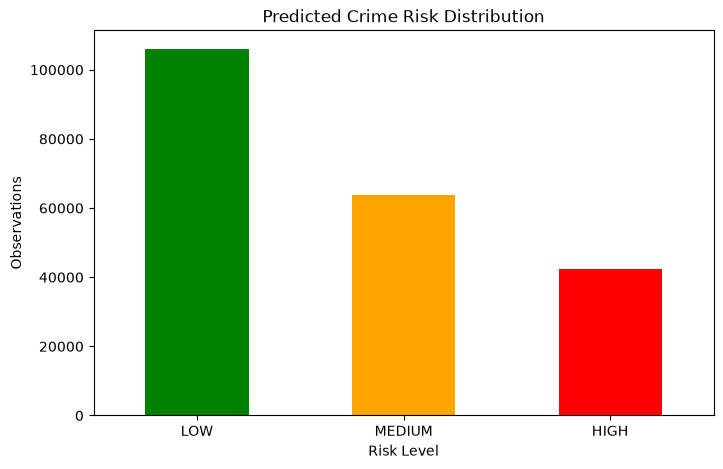

In [45]:
risk_distribution.plot(
    kind='bar',
    figsize=(8, 5),
    color=[
        'green',
        'orange',
        'red'
    ]
)

plt.title('Predicted Crime Risk Distribution')
plt.xlabel('Risk Level')
plt.ylabel('Observations')
plt.xticks(rotation=0)

plt.show()


In [46]:
latest_week = model_data['week'].max()

latest_risk = (
    model_data[
        model_data['week'] == latest_week
    ]
    .copy()
)

print("Week:", latest_week)
print("Areas:", len(latest_risk))

Week: 2026-09-28 00:00:00
Areas: 734


In [47]:
latest_risk = (
    latest_risk
    .sort_values(
        'predicted_crimes',
        ascending=False
    )
    .reset_index(drop=True)
)

latest_risk['risk_rank'] = (
    np.arange(1, len(latest_risk) + 1)
)

latest_risk[
    [
        'risk_rank',
        'grid_id',
        'grid_lat',
        'grid_lon',
        'predicted_crimes',
        'risk_level'
    ]
].head(20)

,risk_rank,grid_id,grid_lat,grid_lon,predicted_crimes,risk_level
0,1,41.89_-87.63,41.89,-87.63,62.602369,HIGH
1,2,41.88_-87.63,41.88,-87.63,51.340319,HIGH
2,3,41.89_-87.62,41.89,-87.62,31.185149,HIGH
3,4,41.9_-87.63,41.90,-87.63,26.753945,HIGH
4,5,41.87_-87.63,41.87,-87.63,21.254981,HIGH
5,6,41.77_-87.58,41.77,-87.58,19.685047,HIGH
6,7,41.75_-87.61,41.75,-87.61,19.665037,HIGH
7,8,41.76_-87.56,41.76,-87.56,19.576235,HIGH
8,9,41.88_-87.75,41.88,-87.75,19.222479,HIGH
9,10,41.75_-87.6,41.75,-87.60,19.001981,HIGH


In [48]:
import folium
risk_map = folium.Map(
    location=[
        spatial['latitude'].mean(),
        spatial['longitude'].mean()
    ],
    zoom_start=10,
    tiles='OpenStreetMap'
)

risk_colors = {
    'LOW': 'green',
    'MEDIUM': 'orange',
    'HIGH': 'red'
}

In [49]:
for _, row in latest_risk.iterrows():

    color = risk_colors[
        row['risk_level']
    ]

    folium.CircleMarker(
        location=[
            row['grid_lat'],
            row['grid_lon']
        ],

        radius=6,

        color=color,

        fill=True,

        fill_color=color,

        fill_opacity=0.65,

        popup=folium.Popup(
            f"""
            <b>Risk Rank:</b>
            {int(row['risk_rank'])}<br>

            <b>Grid:</b>
            {row['grid_id']}<br>

            <b>Predicted Crimes:</b>
            {row['predicted_crimes']:.2f}<br>

            <b>Risk:</b>
            {row['risk_level']}
            """,
            max_width=250
        )

    ).add_to(risk_map)

In [50]:
risk_map


In [51]:
latest_risk.to_csv(
    "../data/latest_area_risk.csv",
    index=False
)

print("Area risk predictions saved ✅")

Area risk predictions saved ✅


In [52]:
risk_map.save(
    "predicted_area_risk_map.html"
)

print("Risk map saved ✅")

Risk map saved ✅


In [53]:
import joblib
import os

os.makedirs(
    "../models",
    exist_ok=True
)

joblib.dump(
    final_area_model,
    "../models/area_risk_model.joblib"
)

joblib.dump(
    features,
    "../models/area_risk_features.joblib"
)

print("Area-risk model saved ✅")

Area-risk model saved ✅


In [54]:
risk_thresholds = {
    'low_medium': float(low_threshold),
    'medium_high': float(high_threshold)
}

joblib.dump(
    risk_thresholds,
    "../models/area_risk_thresholds.joblib"
)

print("Risk thresholds saved ✅")

Risk thresholds saved ✅


In [55]:
files_to_check = [
    "../models/area_risk_model.joblib",
    "../models/area_risk_features.joblib",
    "../models/area_risk_thresholds.joblib",
    "../data/latest_area_risk.csv"
]

for file in files_to_check:
    print(
        file,
        "→",
        os.path.exists(file)
    )

../models/area_risk_model.joblib → True
../models/area_risk_features.joblib → True
../models/area_risk_thresholds.joblib → True
../data/latest_area_risk.csv → True


Conclusion
A weekly spatio-temporal crime forecasting model was developed using stable geographic grid cells and historical crime activity.

The geographic resolution was selected after comparing alternative grid sizes to reduce excessive spatial sparsity.

The final model uses spatial coordinates, temporal variables, historical crime lags, rolling statistics and historical activity.

The HistGradientBoosting model outperformed the previous-week historical baseline and remained consistently better across multiple temporal validation periods.

Predicted crime intensity is converted into relative LOW, MEDIUM and HIGH risk levels for visualization and downstream Crime Copilot use.

Risk levels represent aggregate area-level historical patterns and should not be interpreted as predictions of individual criminal events.

In [56]:
grid_week.to_csv(
    "../data/grid_week_history.csv",
    index=False
)